# **Iris Dataset Analysis**

**Goal:** Explore the Iris data, visualize how species differ and build a simple classifier.

# Outline:
1.   Setup
2.   Load the dataset
3.   Exploratory data analysis (EDA)
4.   Preprocessing + train/test split
5.  Baseline models
6.  Evaluation
7. Unsupervised view (PCA + k-means)
8. Conclusions

## **1. Setup**

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## **2. Load the data**

In [5]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [6]:
print(df.shape)
df.info()

(150, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [7]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [8]:
print("Missing values:\n", df.isna().sum())
print("\nClass balance:\n", df["species"].value_counts())

Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Class balance:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## **3. Exploratory data analysis**

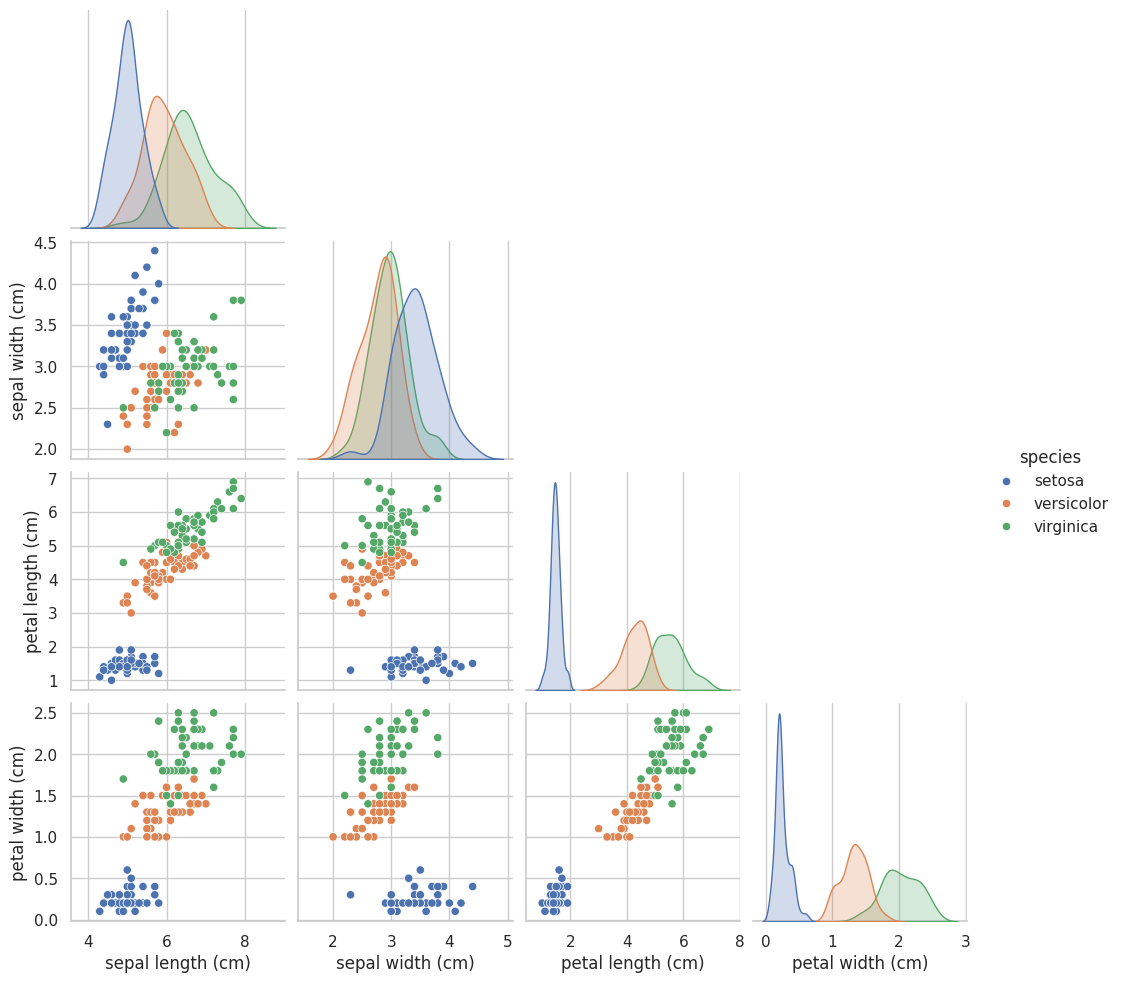

In [9]:
#pairwise relationships
sns.pairplot(df.drop(columns="target"), hue="species", corner=True)
plt.show()

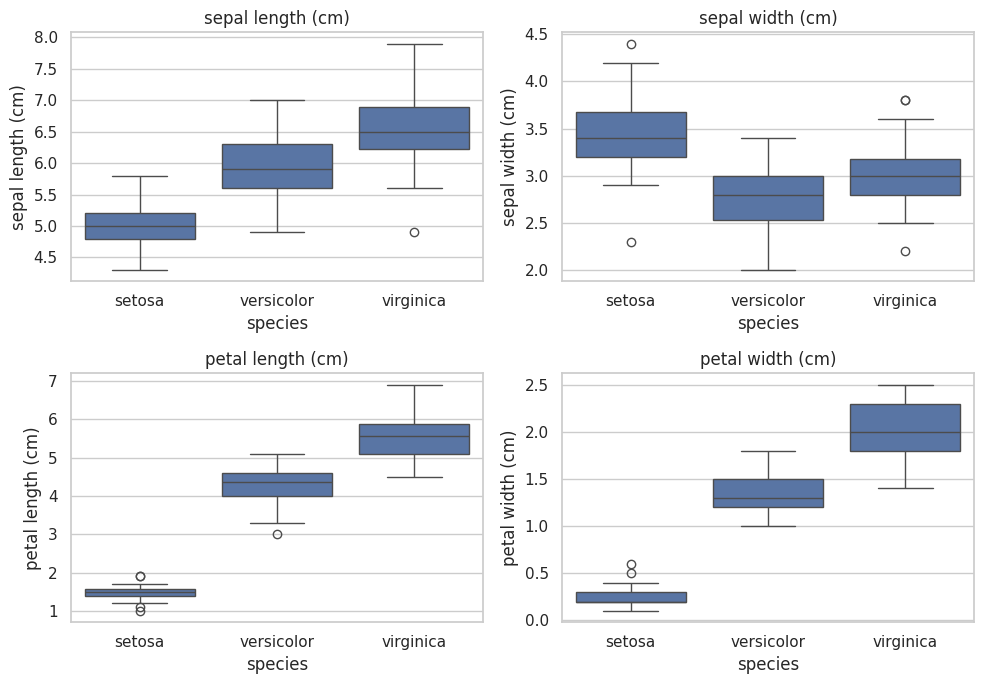

In [10]:
#feature distributions by species
features = iris.feature_names
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, feat in zip(axes.flat, features):
    sns.boxplot(data=df, x="species", y=feat, ax=ax)
    ax.set_title(feat)
plt.tight_layout()
plt.show()

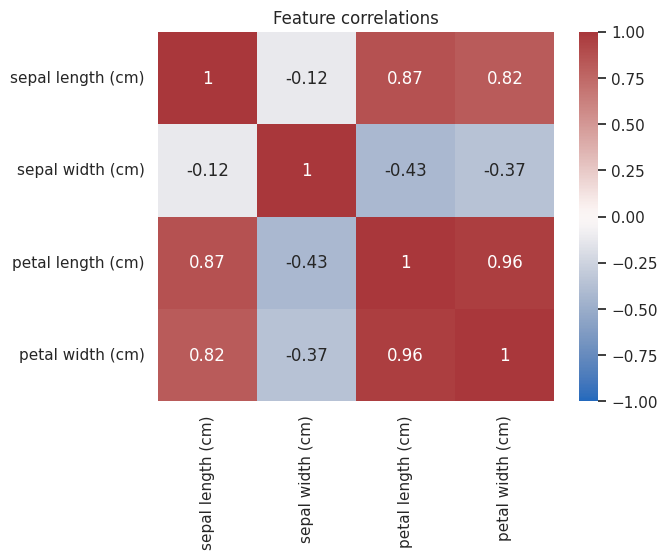

In [11]:
#correlations
sns.heatmap(df[features].corr(), annot=True, cmap="vlag", vmin=-1, vmax=1)
plt.title("Feature correlations")
plt.show()

## **4. Preprocessing & train/test split**

In [12]:
X = df[features]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_train.shape, X_test.shape

((120, 4), (30, 4))

## **5. Baseline Models**

In [13]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "k-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}

results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5)
    results[name] = (scores.mean(), scores.std())

pd.DataFrame(results, index=["cv_mean_acc", "cv_std"]).T.round(3)

,cv_mean_acc,cv_std
Logistic Regression,0.958,0.026
k-NN (k=5),0.967,0.031
Decision Tree,0.933,0.020


## **6. Evaluation on Test Set**

In [14]:
best_name = max(results, key=lambda k: results[k][0])
best_model = models[best_name].fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print(f"Best model: {best_name}\n")
print(classification_report(y_test, y_pred))

Best model: k-NN (k=5)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



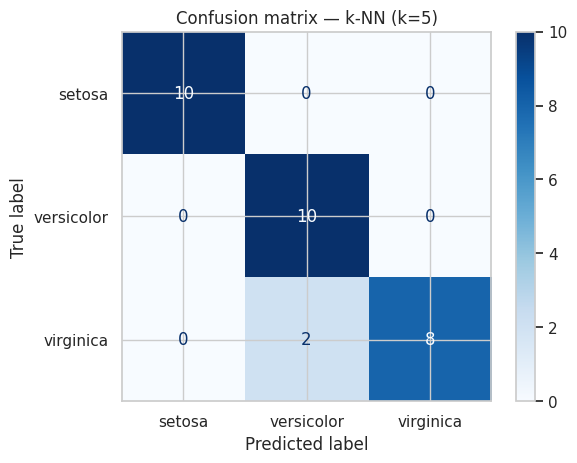

In [15]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title(f"Confusion matrix — {best_name}")
plt.show()

## **7. Unsupervised View**

Explained variance ratio: [0.73  0.229]


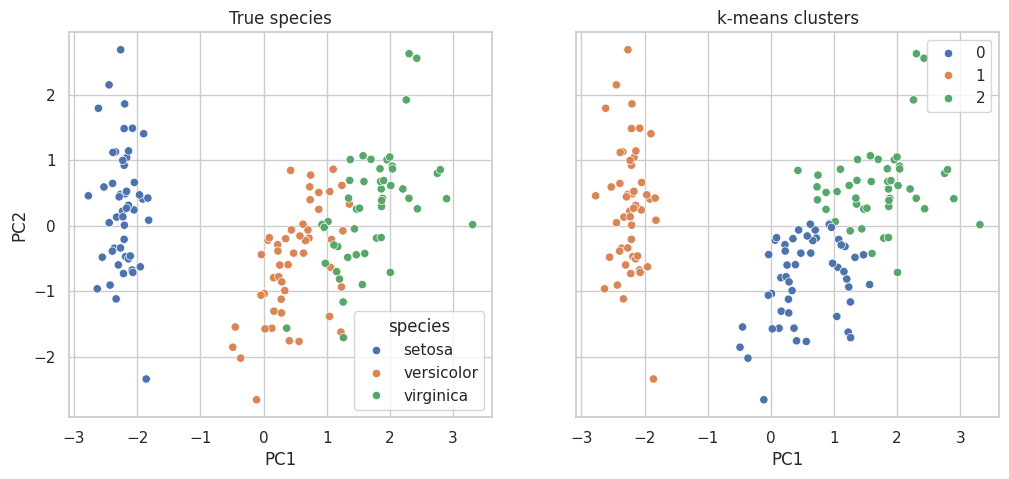

cluster,0,1,2
species,,,
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36


In [16]:
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))

kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, ax=axes[0]).set_title("True species")
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans.labels_, palette="deep", ax=axes[1]).set_title("k-means clusters")
for ax in axes: ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.show()

pd.crosstab(y, kmeans.labels_, rownames=["species"], colnames=["cluster"])

## **8. Conclusions**



*  **The species differ mostly in petal size**. Petal length and width separate the species far better than the sepal measurements do, and the two petal features are strongly correlated (r ≈ 0.96). Setosa is completely separable from the other two. Versicolor and virginica overlap.

*  **Simple models do very well**. With 5-fold cross-validation, k-NN (k=5) scored 96.7% accuracy, logistic regression 95.8%, and a depth-3 decision tree 93.3%. The differences are within about one standard deviation, so all three are reasonable choices.

*   **The test set confirms the overlap.** On held-out data, k-NN reached 93% accuracy (28 of 30 correct). Both errors were virginica flowers predicted as versicolor, and setosa was classified perfectly.

*  **The structure shows up even without labels**. Two principal components explain about 96% of the variance (73% and 23%). K-means put all 50 setosa in their own cluster, but it mixed up 25 of the 100 versicolor and virginica flowers. This shows that the overlap is in the data itself, not a weakness of any one model.

*   **Limitations**: The dataset is small (150 samples, 30 in the test set), so a single misclassification shifts test accuracy by about 3%. It also has only four features, all measured in one region.



**Next steps**: Tune k with a grid search, try an SVM, and plot decision boundaries in petal space to show where versicolor and virginica blur together.

